In [ ]:
# Preprocessing
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import joblib
!pip install kagglehub
import kagglehub
import os

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [ ]:
# 0) Downlading and Loading Dataset

path = kagglehub.dataset_download("varishabatool/data-set")
print("Path to dataset files:", path)

# Build full file path
file_path = os.path.join(path, "insurance.csv")

# Load the dataset
df = pd.read_csv(file_path)
print("Initial shape:", df.shape)
print(df.head())

Using Colab cache for faster access to the 'data-set' dataset.
Path to dataset files: /kaggle/input/data-set
Initial shape: (1338, 7)
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520


In [ ]:
# 1) Drop duplicates
df = df.drop_duplicates()

In [ ]:
# 2) Quick tidy: lowercase & strip (if strings exist)
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].astype(str).str.strip().str.lower()

In [ ]:
# 3) Missing values check
print("Missing counts:\n", df.isnull().sum())

Missing counts:
 age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [ ]:
# 4) Map binary columns (sex, smoker)
df['sex'] = df['sex'].map({'male':0, 'female':1})
df['smoker'] = df['smoker'].map({'no':0, 'yes':1})

In [ ]:
# 5) Outlier capping function (IQR)
def cap_outliers_iqr(series, k=1.5):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - k*iqr
    upper = q3 + k*iqr
    return series.clip(lower, upper)

# Apply to numeric columns that may have outliers
for col in ['bmi', 'age', 'children']:
    if col in df.columns:
        df[col] = cap_outliers_iqr(df[col])


In [ ]:
# 6) Optional feature engineering
if {'bmi','smoker'}.issubset(df.columns):
    df['bmi_smoker'] = df['bmi'] * df['smoker']

In [ ]:
# 7) Define x, y
target = 'charges'
x = df.drop(columns=[target])
y = df[target].copy()

In [ ]:
# 8) Column lists
categorical_cols = ['sex', 'smoker']   # no 'region'
numeric_cols = ['age', 'bmi', 'children', 'bmi_smoker']

In [ ]:
# 9) Pipelines
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(drop='first'), categorical_cols)
    ]
)

In [ ]:
# 10) Fit & transform (this applies numeric+categorical transforms in one shot)
x_trans = preprocessor.fit_transform(x)

In [ ]:
# 11) Build final feature names for DataFrame (helpful to inspect)

# Numeric names:
num_names = numeric_features

# Categorical names:
cat_ohe = preprocessor.named_transformers_['cat'].named_steps['onehot']
cat_names = list(cat_ohe.get_feature_names_out(categorical_features)) if categorical_features else []

# Passthrough names (columns not in numeric_features or categorical_features)
passthrough_cols = [c for c in x.columns if c not in numeric_features + categorical_features]
all_feature_names = num_names + cat_names + passthrough_cols

# Convert to DataFrame
x_clean = pd.DataFrame(x_trans, columns=all_feature_names)
print("Transformed shape:", x_clean.shape)
print(x_clean.head())

AttributeError: 'OneHotEncoder' object has no attribute 'named_steps'

In [ ]:
# 12) Sanity check: no missing values
print("Any NaNs after transform?", x_clean.isnull().values.any())

Any NaNs after transform? False


In [ ]:
# 13) Train-test split and save
x_train, x_test, y_train, y_test = train_test_split(x_clean, y, test_size=0.2, random_state=42)
pd.concat([x_train, y_train.reset_index(drop=True)], axis=1).to_csv('insurance_clean_train.csv', index=False)
pd.concat([x_test, y_test.reset_index(drop=True)], axis=1).to_csv('insurance_clean_test.csv', index=False)
print("Saved cleaned train/test CSVs.")

Saved cleaned train/test CSVs.


In [ ]:
# 14) Persist preprocessing pipeline (re-use for inference)
joblib.dump(preprocessor, 'insurance_preprocessor.pkl')
print("Saved preprocessor: insurance_preprocessor.pkl")

Saved preprocessor: insurance_preprocessor.pkl


In [ ]:
from google.colab import files

# Download training set
files.download("insurance_clean_train.csv")

# Download test set
files.download("insurance_clean_test.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Data Modelling

In [ ]:
#Train the model
model.fit(x_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children',
                                                   'bmi_smoker']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['sex', 'smoker'])])),
                ('model', RandomForestRegressor())])

In [ ]:
# Predict
y_pred = model.predict(x_test)

EDA

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

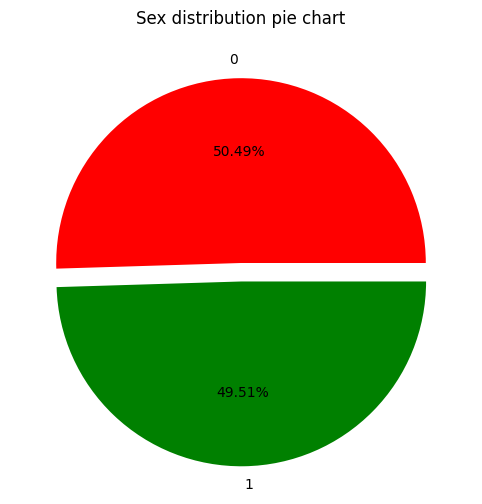

In [ ]:
plt.figure(figsize=(8,6))
plt.pie(
    x=df['sex'].value_counts(),
    labels=df['sex'].value_counts().index,
    autopct="%1.2f%%",
    colors=['red','green'],
    explode=(0,0.1)
)
plt.title("Sex distribution pie chart")
plt.show()


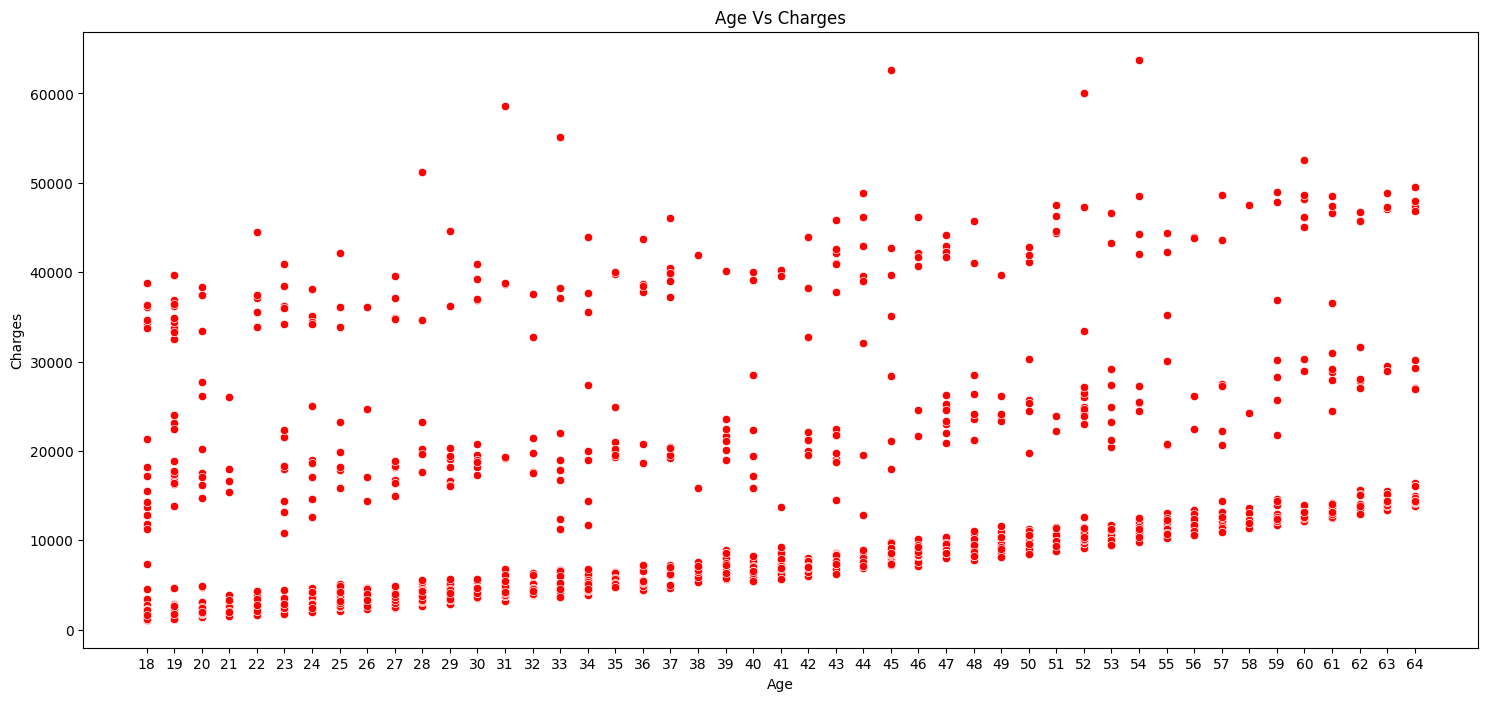

In [ ]:
plt.figure(figsize=(18,8))
sns.scatterplot(data=df,x='age',y='charges',color='red')
plt.title("Age Vs Charges")
plt.xlabel("Age")
plt.ylabel("Charges")
plt.xticks([i for i in range(18,65)])
plt.show()

*The older a person is, the more expensive their health insurance will be.*

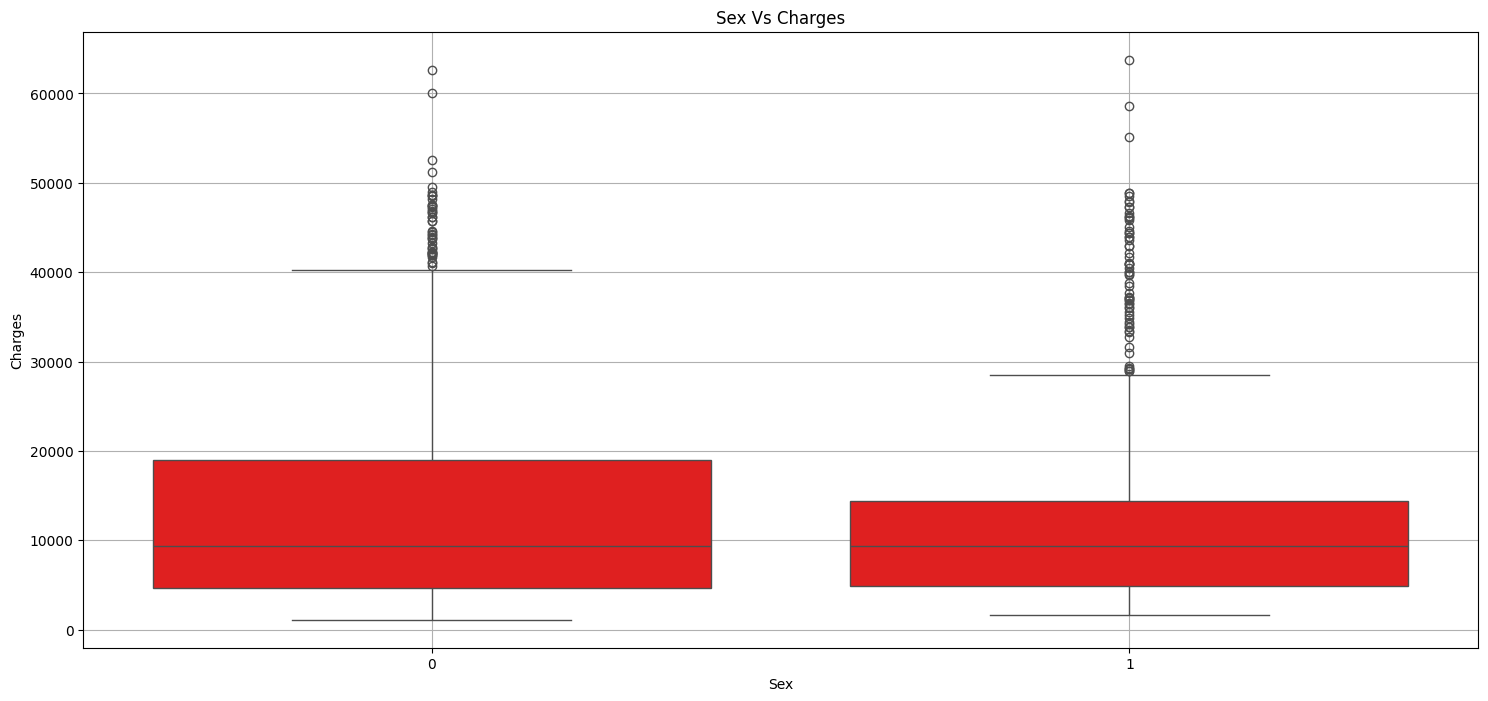

In [ ]:
plt.figure(figsize=(18,8))
sns.boxplot(data=df,x='sex',y='charges',color='red')
plt.title("Sex Vs Charges")
plt.xlabel("Sex")
plt.ylabel("Charges")
plt.grid('y')
plt.show()

*The average fees paid by men are higher than those paid by women, but some women pay fees that are considered high and outside the specified range.*

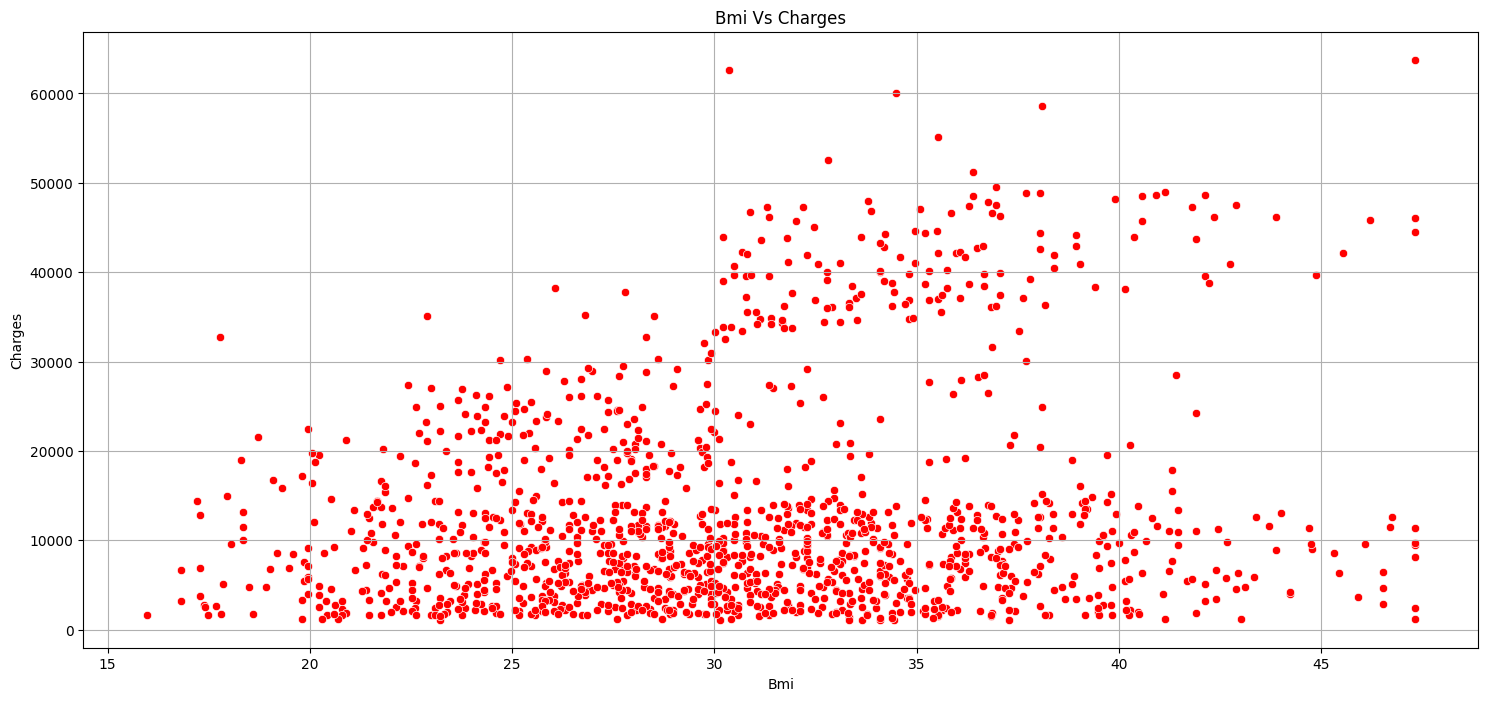

In [ ]:
plt.figure(figsize=(18,8))
sns.scatterplot(data=df,x='bmi',y='charges',color='red')
plt.title("Bmi Vs Charges")
plt.xlabel("Bmi")
plt.ylabel("Charges")
plt.grid('y')
plt.show()

*bmi(20:45) With the increased (bmi) increas (charges),bmi(45:end) the charges it decrease with some outliers*

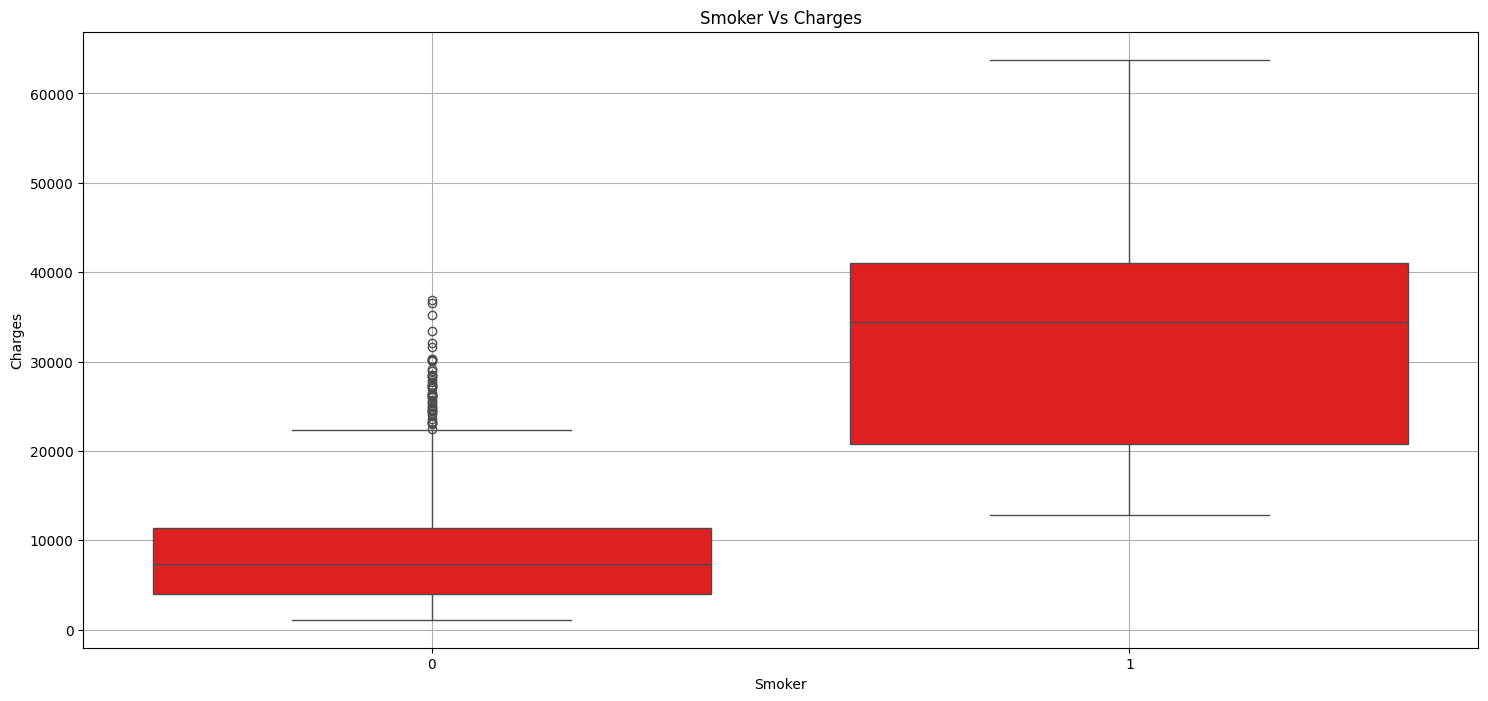

In [ ]:
plt.figure(figsize=(18,8))
sns.boxplot(data=df,x='smoker',y='charges',color='red')
plt.title("Smoker Vs Charges")
plt.xlabel("Smoker")
plt.ylabel("Charges")
plt.grid('y')
plt.show()

*People who smoke pay more health insurance fees than people who do not smoke, which indicates that smoking affects health fees.*

Correlation Matrix

<Axes: >

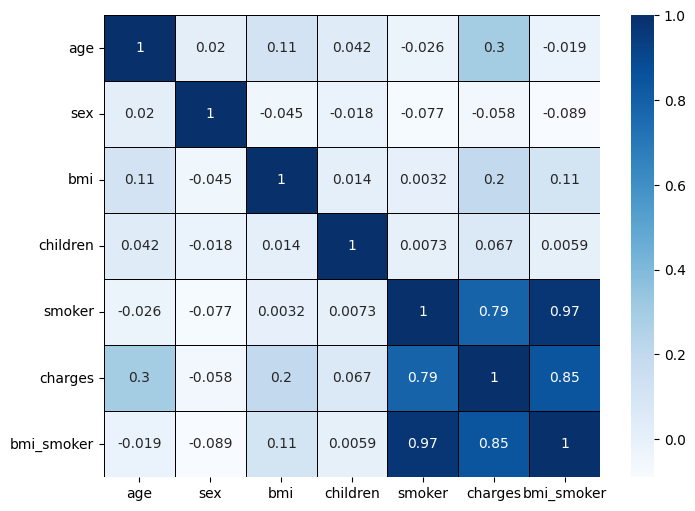

In [ ]:
num_col = df.select_dtypes(include ='number')
corr_matrix = num_col.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot = True, cmap= 'Blues', linecolor = 'black', linewidth = 0.50)

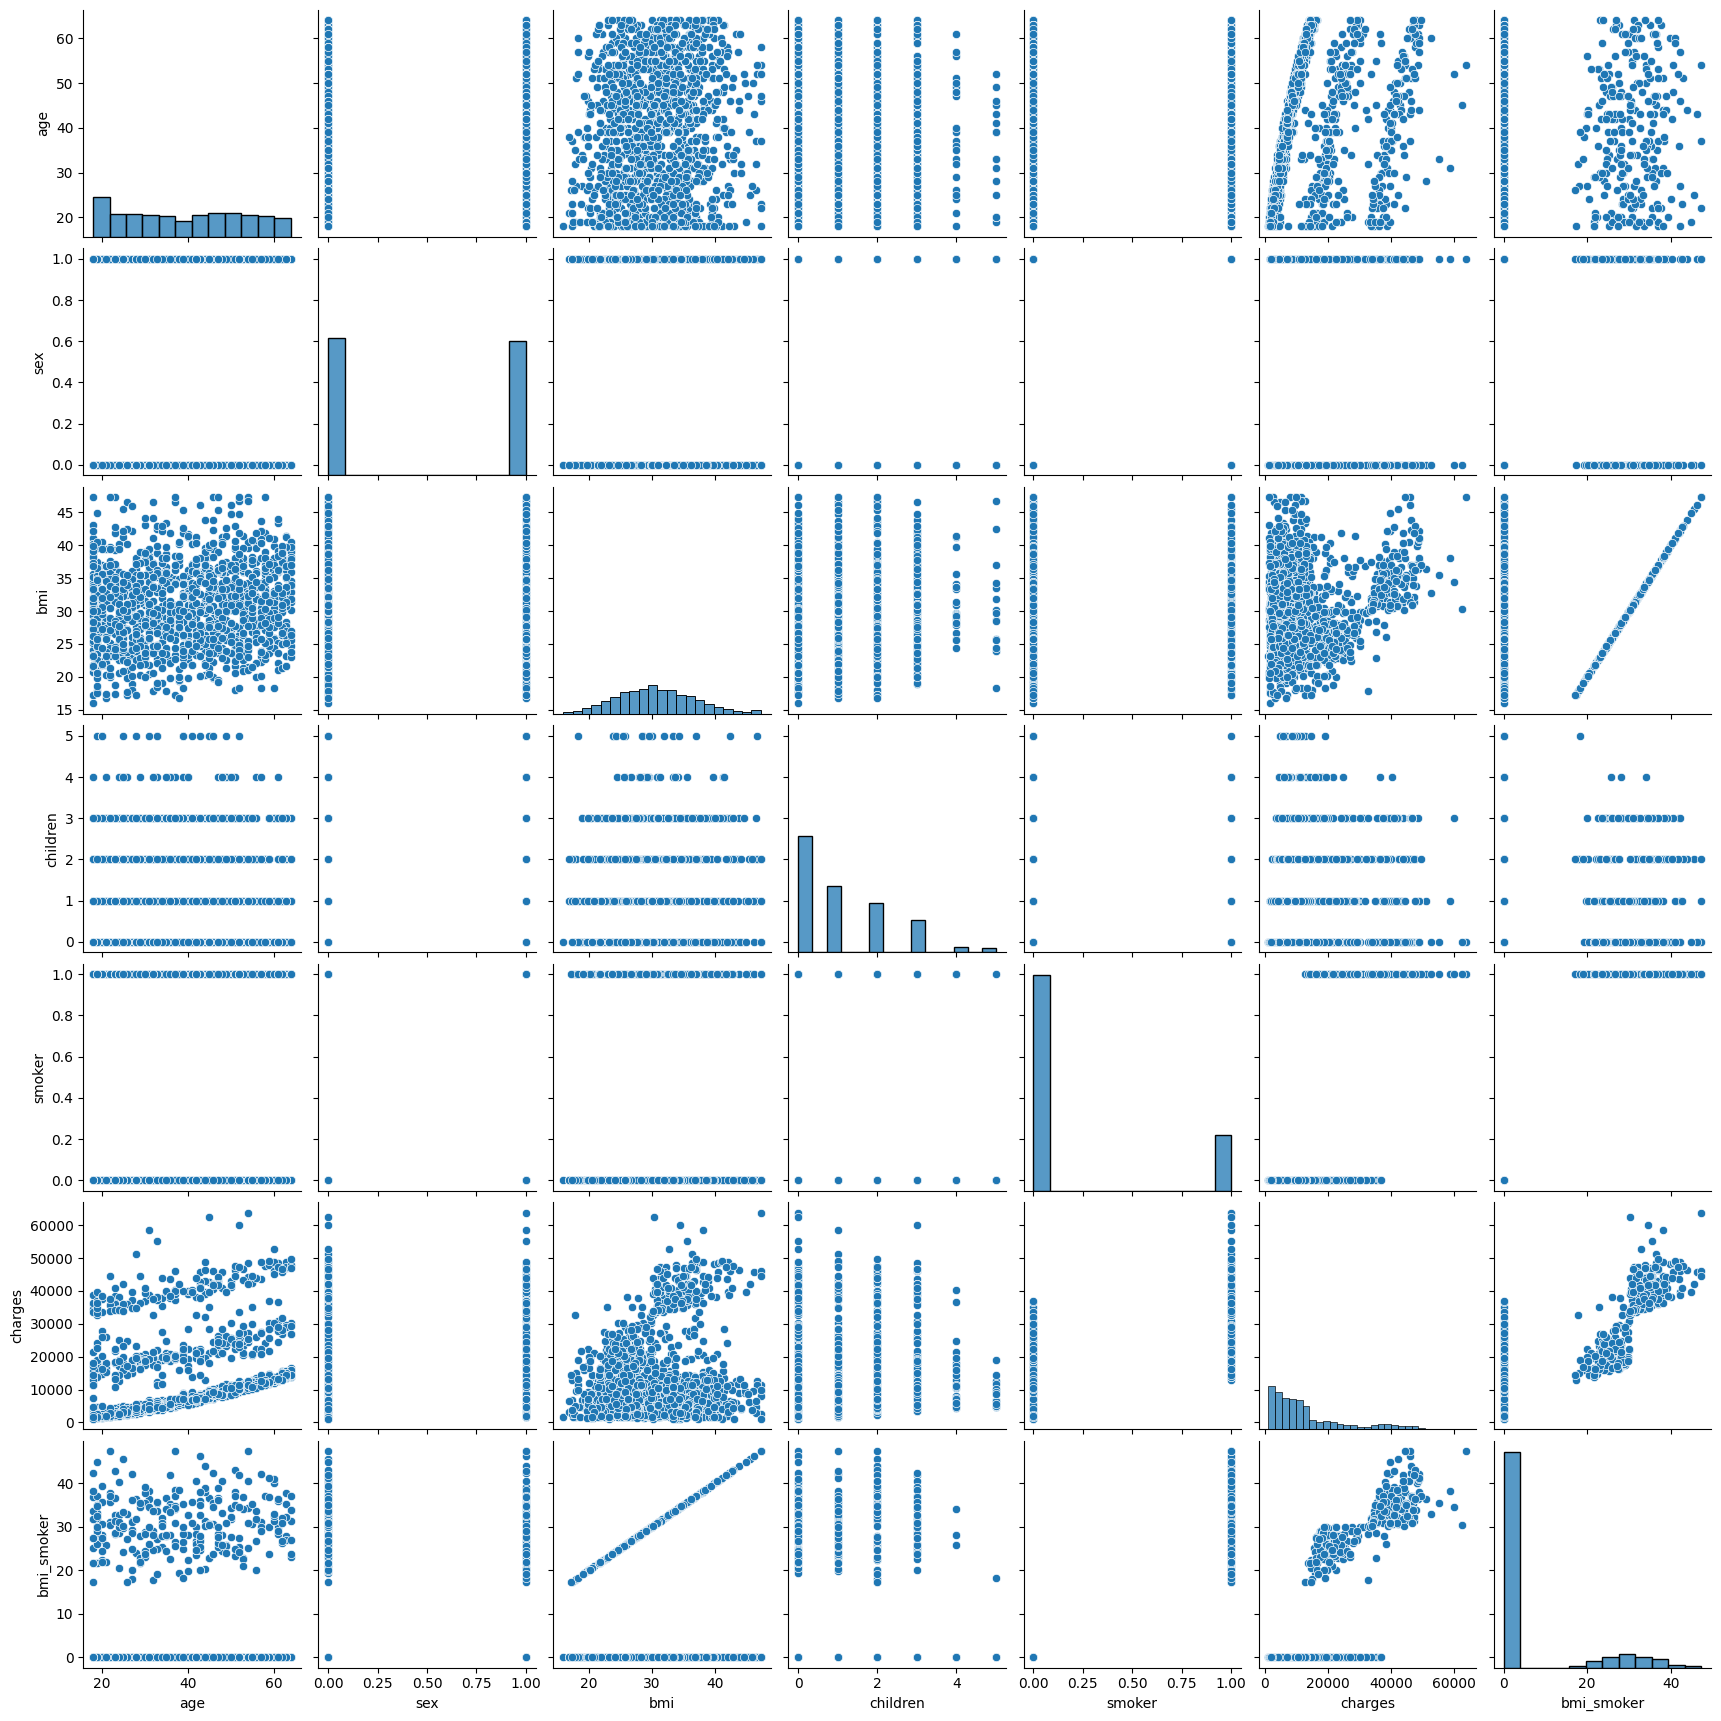

In [ ]:
def cap_outliers(df):
    for col in num_col:
        Q1, Q3 = df[col].quantile([0.25, 0.75])
        IQR = Q3 - Q1
        lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5* IQR
        df[col] = df[col].clip(lower, upper)
    return df

df = cap_outliers(df)

sns.pairplot(num_col)

/tmp/ipython-input-3184238587.py:7: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[col])
/tmp/ipython-input-3184238587.py:7: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(df[col])


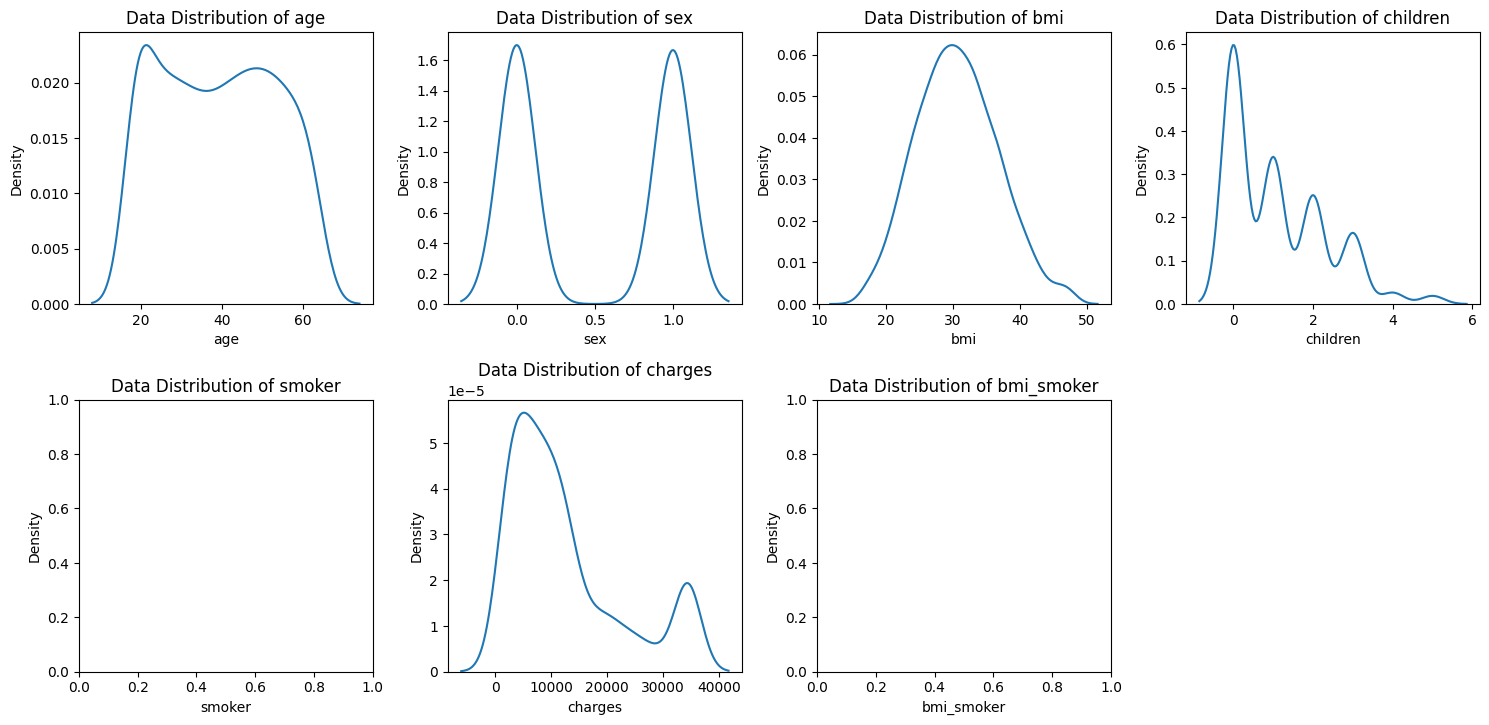

In [ ]:
plt.figure(figsize=(15,40))
index = 1

for col in num_col:
    plt.subplot(11,4, index)
    plt.title(f'Data Distribution of {col}')
    sns.kdeplot(df[col])
    plt.tight_layout()
    index +=1

Data Modeling and Prediction

In [ ]:
# Define models with pipelines
models = {
    'Linear Regression': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', LinearRegression())
    ]),
    'Random Forest': Pipeline([
        ('preprocessor', preprocessor),
        ('regressor', RandomForestRegressor(n_estimators=100, random_state=42))
    ])
}


In [ ]:
# Train and evaluate models
results = {}

for name, pipeline in models.items():
    try:
        # Train model
        pipeline.fit(x_train, y_train)

        # Make predictions
        y_pred = pipeline.predict(x_test)

        # Calculate metrics
        mae = mean_absolute_error(y_test, y_pred)
        mse = mean_squared_error(y_test, y_pred)
        rmse = np.sqrt(mse)
        r2 = r2_score(y_test, y_pred)

        results[name] = {
            'MAE': mae,
            'MSE': mse,
            'RMSE': rmse,
            'R2': r2
        }

        # Print results
        print(f"\n{name}:")
        print(f"  MAE: {mae:,.2f}")
        print(f"  RMSE: {rmse:,.2f}")
        print(f"  R² Score: {r2:.4f}")

    except Exception as e:
        print(f"Error in {name}: {e}")
        results[name] = {
            'MAE': np.nan,
            'MSE': np.nan,
            'RMSE': np.nan,
            'R2': np.nan
        }


Linear Regression:
  MAE: 2,770.64
  RMSE: 4,537.77
  R² Score: 0.8674

Random Forest:
  MAE: 2,536.85
  RMSE: 4,657.76
  R² Score: 0.8603


Model Comparision


In [ ]:
results_df = pd.DataFrame(results).T
print("\n" + "="*50)
print("MODEL COMPARISON")
print("="*50)
print(results_df)


MODEL COMPARISON
                           MAE           MSE         RMSE        R2
Linear Regression  2770.638237  2.059137e+07  4537.771368  0.867365
Random Forest      2536.845410  2.169471e+07  4657.757910  0.860258


PREDICTIONS ANALYSIS

In [ ]:
print("\n" + "="*50)
print("PREDICTIONS ANALYSIS")
print("="*50)

# Use the best model for detailed analysis (skip models with NaN results)
valid_results = results_df.dropna()
if not valid_results.empty:
    best_model_name = valid_results['R2'].idxmax()
    best_pipeline = models[best_model_name]

    # Fit on full training data and predict
    best_pipeline.fit(x_train, y_train)
    y_pred = best_pipeline.predict(x_test)

    # Create comparison dataframe
    comparison_df = pd.DataFrame({
        'Actual': y_test,
        'Predicted': y_pred,
        'Residual': y_test - y_pred
    })

    print(f"Using best model: {best_model_name}")
    print(f"Sample predictions:")
    print(comparison_df.head(10))


PREDICTIONS ANALYSIS
Using best model: Linear Regression
Sample predictions:
           Actual     Predicted     Residual
764    9095.06825  10588.814022 -1493.745772
887    5272.17580   7331.145610 -2058.969810
890   29330.98315  33048.990328 -3718.007178
1293   9301.89355  10813.775187 -1511.881637
259   33750.29180  28105.622300  5644.669500
1312   4536.25900   6877.990955 -2341.731955
899    2117.33885   2785.682426  -668.343576
752   14210.53595  14267.754676   -57.218726
1286   3732.62510   5108.432826 -1375.807726
707   10264.44210  11630.657349 -1366.215249


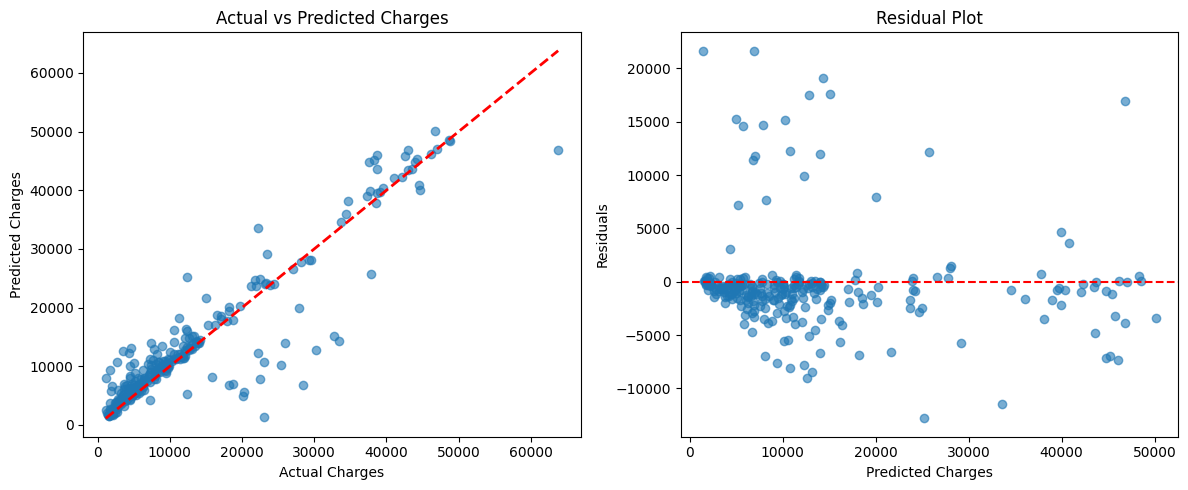

In [ ]:
# Pick a model to visualize
chosen_model = models['Random Forest']

# Train again (to be safe)
chosen_model.fit(x_train, y_train)
y_pred = chosen_model.predict(x_test)

# Create residuals dataframe
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
})
comparison_df['Residual'] = comparison_df['Actual'] - comparison_df['Predicted']

# Plot Actual vs Predicted and Residuals
plt.figure(figsize=(12, 5))

# Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(comparison_df['Actual'], comparison_df['Predicted'], alpha=0.6)
plt.plot(
    [comparison_df['Actual'].min(), comparison_df['Actual'].max()],
    [comparison_df['Actual'].min(), comparison_df['Actual'].max()],
    'r--', lw=2
)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')

# Residual Plot
plt.subplot(1, 2, 2)
plt.scatter(comparison_df['Predicted'], comparison_df['Residual'], alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Charges')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.tight_layout()
plt.show()


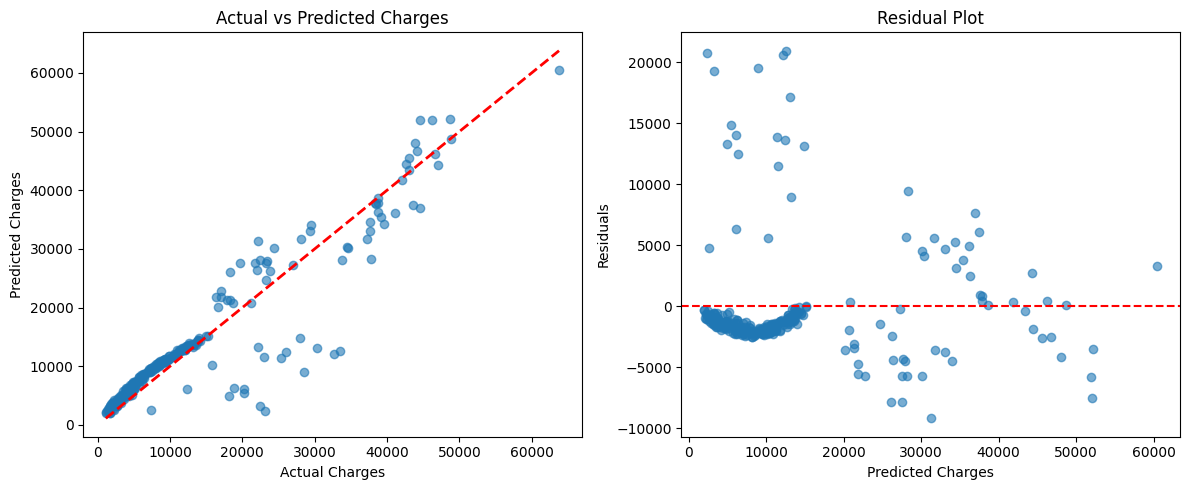

In [ ]:
# Pick a model to visualize
chosen_model = models['Linear Regression']

# Train again (to be safe)
chosen_model.fit(x_train, y_train)
y_pred = chosen_model.predict(x_test)

# Create residuals dataframe
comparison_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred,
})
comparison_df['Residual'] = comparison_df['Actual'] - comparison_df['Predicted']

# Plot Actual vs Predicted and Residuals
plt.figure(figsize=(12, 5))

# Actual vs Predicted
plt.subplot(1, 2, 1)
plt.scatter(comparison_df['Actual'], comparison_df['Predicted'], alpha=0.6)
plt.plot(
    [comparison_df['Actual'].min(), comparison_df['Actual'].max()],
    [comparison_df['Actual'].min(), comparison_df['Actual'].max()],
    'r--', lw=2
)
plt.xlabel('Actual Charges')
plt.ylabel('Predicted Charges')
plt.title('Actual vs Predicted Charges')

# Residual Plot
plt.subplot(1, 2, 2)
plt.scatter(comparison_df['Predicted'], comparison_df['Residual'], alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Charges')
plt.ylabel('Residuals')
plt.title('Residual Plot')

plt.tight_layout()
plt.show()


KEY INSIGHTS SUMMARY

In [ ]:
# Smoking impact
smoker_stats = df.groupby('smoker')['charges'].agg(['mean', 'count'])

# BMI categories
bins = [0, 18.5, 24.9, 29.9, 100]
labels = ['Underweight', 'Normal', 'Overweight', 'Obese']
df['bmi_category'] = pd.cut(df['bmi'], bins=bins, labels=labels)
bmi_stats = df.groupby('bmi_category')['charges'].agg(['mean', 'count'])

# Smoking + BMI combination
combined_stats = df.groupby(['smoker', 'bmi_category'])['charges'].mean().unstack()

rf_model = models['Random Forest']
rf_model.fit(x_train, y_train)

# Get transformed feature matrix
X_transformed = rf_model.named_steps['preprocessor'].transform(x_train)
n_features = X_transformed.shape[1]

# Create placeholder feature names that match the length
all_features = [f'feature_{i}' for i in range(n_features)]

importances = rf_model.named_steps['regressor'].feature_importances_
feature_importance = pd.DataFrame({
    'feature': all_features,
    'importance': importances
}).sort_values(by='importance', ascending=False)


/tmp/ipython-input-485974178.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  bmi_stats = df.groupby('bmi_category')['charges'].agg(['mean', 'count'])
/tmp/ipython-input-485974178.py:11: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  combined_stats = df.groupby(['smoker', 'bmi_category'])['charges'].mean().unstack()


In [ ]:
print("\n" + "="*50)
print("KEY INSIGHTS SUMMARY")
print("="*50)

print("1. Smoking has the most significant impact on medical charges:")
print(f"   - Smokers pay on average ${smoker_stats.loc[1, 'mean']:,.2f}")
print(f"   - Non-smokers pay on average ${smoker_stats.loc[0, 'mean']:,.2f}")
print(f"   - Difference: ${smoker_stats.loc[1, 'mean'] - smoker_stats.loc[0, 'mean']:,.2f}")

print("\n2. BMI categories show clear cost progression:")
for category in ['Underweight', 'Normal', 'Overweight', 'Obese']:
    if category in bmi_stats.index:
        avg_charge = bmi_stats.loc[category, 'mean']
        print(f"   - {category}: ${avg_charge:,.2f}")

print("\n3. The combination of smoking and high BMI leads to highest charges:")
if not combined_stats.empty:
    max_charge_combination = combined_stats.max().max()
    print(f"   - Highest average charges: ${max_charge_combination:,.2f}")

print("\n4. Best performing model:")
if not valid_results.empty:
    best_model_name = valid_results['R2'].idxmax()
    best_r2 = valid_results.loc[best_model_name, 'R2']
    print(f"   - {best_model_name} with R² score of {best_r2:.4f}")
else:
    print("   - No valid models available")

print("\n5. Most important features for prediction:")
for i, row in feature_importance.head(3).iterrows():
    print(f"   - {row['feature']}: {row['importance']:.3f}")



KEY INSIGHTS SUMMARY
1. Smoking has the most significant impact on medical charges:
   - Smokers pay on average $32,050.23
   - Non-smokers pay on average $8,434.27
   - Difference: $23,615.96

2. BMI categories show clear cost progression:
   - Underweight: $8,657.62
   - Normal: $10,404.90
   - Overweight: $11,006.81
   - Obese: $15,491.54

3. The combination of smoking and high BMI leads to highest charges:
   - Highest average charges: $41,355.87

4. Best performing model:
   - Linear Regression with R² score of 0.8674

5. Most important features for prediction:
   - feature_3: 0.762
   - feature_0: 0.132
   - feature_1: 0.072


Prediction Model Examples

In [ ]:
print("\n" + "="*50)
print("PREDICTION EXAMPLES")
print("="*50)

# Create example cases
example_cases = pd.DataFrame({
    'age': [25, 45, 60, 35],
    'sex': ['female', 'male', 'female', 'male'],
    'bmi': [22.0, 35.0, 28.0, 19.0],
    'children': [0, 2, 1, 0],
    'smoker': [0, 1, 0, 0],  # numeric 0 = non-smoker, 1 = smoker
    'region': ['southeast', 'northwest', 'southwest', 'northeast']
})

# Map categorical columns to numeric as used in training
example_cases['sex'] = example_cases['sex'].map({'female': 0, 'male': 1})
example_cases['smoker'] = example_cases['smoker'].astype(int)

# Add engineered feature
example_cases['bmi_smoker'] = example_cases['bmi'] * example_cases['smoker']

# Predict using best_pipeline
example_predictions = best_pipeline.predict(example_cases)
example_cases['predicted_charges'] = example_predictions


print("Example cases for prediction:")
print(example_cases)

# Use the best performing pipeline
best_pipeline = models['Random Forest']  # make sure this is already fitted

# Predict charges
example_predictions = best_pipeline.predict(example_cases)
example_cases['predicted_charges'] = example_predictions

print("\nPredicted charges for example cases:")
for i, row in example_cases.iterrows():
    print(f"Case {i+1}: {row['age']}yo {row['sex']}, BMI {row['bmi']}, {row['children']} children, "
          f"smoker: {row['smoker']} -> Predicted: ${row['predicted_charges']:,.2f}")



PREDICTION EXAMPLES
Example cases for prediction:
   age  sex   bmi  children  smoker     region  bmi_smoker  predicted_charges
0   25    0  22.0         0       0  southeast         0.0       16561.704911
1   45    1  35.0         2       1  northwest        35.0       49301.301399
2   60    0  28.0         1       0  southwest         0.0       16356.508214
3   35    1  19.0         0       0  northeast         0.0       17381.625728

Predicted charges for example cases:
Case 1: 25yo 0, BMI 22.0, 0 children, smoker: 0 -> Predicted: $16,561.70
Case 2: 45yo 1, BMI 35.0, 2 children, smoker: 1 -> Predicted: $49,301.30
Case 3: 60yo 0, BMI 28.0, 1 children, smoker: 0 -> Predicted: $16,356.51
Case 4: 35yo 1, BMI 19.0, 0 children, smoker: 0 -> Predicted: $17,381.63
